# Lab 03: Data Exploration

Summary:

1. Data Exploration and initial analysis:
    - Loading the data.
    - Inspecting data shape, column names, and data types, variable types.
    - Viewing basic descriptive statistics and unique values.
    - Subsetting data by rows and columns, and conditional selection.

2. Data Quality Checks:
    - Identifying **missing values**.
    - Checking and correcting **data types**.
    - Detecting and handling **duplicate records**.

4. Data Aggregation and Operations:
    - Summing and aggregating data by columns and rows.
    - Discussing the appropriateness of different operations.

5. Visual Exploration:
    - Plotting univariate distributions (histograms and box plots) for numeric variables.
    - Using matplotlib and seaborn for data visualization.

7. Optional Exercise:
    - Applying the same analysis steps to the project dataset.

In [2]:
# Remember: library imports are ALWAYS at the top of the script, no exceptions!
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

sns.set_theme()

# Context
The data we will be using through the pratical classes comes from a small relational database whose schema can be seen below:

![alt text](../figures/schema.png "Relation database schema")

# Reading the Data

In [3]:
# path to database
my_path = os.path.join("..", "data", "datamining.db")

# connect to the database
conn = sqlite3.connect(my_path)

# the query
query = """
select
    age, 
    income, 
    frq, 
    rcn, 
    mnt, 
    clothes, 
    kitchen, 
    small_appliances, 
    toys, 
    house_keeping,
    dependents, 
    per_net_purchase,
    g.gender, 
    e.education, 
    m.status, 
    r.description
from customers as c
    join genders as g on g.id = c.gender_id
    join education_levels as e on e.id = c.education_id
    join marital_status as m on m.id = c.marital_status_id
    join recommendations as r on r.id = c.recommendation_id
order by c.id;
"""

df = pd.read_sql_query(query, conn)

# Metadata
- *id* - The unique identifier of the customer
- *age* - The year of birht of the customer
- *income* - The income of the customer
- *frq* - Frequency: number of purchases made by the customer
- *rcn* - Recency: number of days since last customer purchase
- *mnt* - Monetary: amount of € spent by the customer in purchases
- *clothes* - Number of clothes items purchased by the customer
- *kitchen* - Number of kitchen items purchased by the customer
- *small_appliances* - Number of small_appliances items purchased by the customer
- *toys* - Number of toys items purchased by the customer
- *house_keeping* - Number of house_keeping items purchased by the customer
- *dependents* - Binary. Whether or not the customer has dependents
- *per_net_purchase* - Percentage of purchases made online
- *education* - Education level of the customer
- *status* - Marital status of the customer
- *gender* - Gender of the customer
- *description* - Last customer's recommendation description

# Initial Analysis

Pandas user guide: https://pandas.pydata.org/pandas-docs/stable/user_guide/index.html

Pandas 10 min tutorial: https://pandas.pydata.org/pandas-docs/stable/user_guide/10min.html

## What are some characteristics of our data?

We can use the `.shape` method to see how much data we have.

It returns a tuple with (nrows, ncols).

In [4]:
# Check the shape
df.shape

(8998, 16)

How to get the names of the columns of the data?

In [5]:
df.columns

Index(['age', 'income', 'frq', 'rcn', 'mnt', 'clothes', 'kitchen',
       'small_appliances', 'toys', 'house_keeping', 'dependents',
       'per_net_purchase', 'gender', 'education', 'status', 'description'],
      dtype='object')

We can use the `.info()` method to get some information about the dataset we have.

In [6]:
# Check the info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8998 entries, 0 to 8997
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   age               8998 non-null   int64 
 1   income            8998 non-null   object
 2   frq               8998 non-null   int64 
 3   rcn               8998 non-null   int64 
 4   mnt               8998 non-null   int64 
 5   clothes           8998 non-null   int64 
 6   kitchen           8998 non-null   int64 
 7   small_appliances  8998 non-null   int64 
 8   toys              8998 non-null   int64 
 9   house_keeping     8998 non-null   int64 
 10  dependents        8998 non-null   object
 11  per_net_purchase  8998 non-null   int64 
 12  gender            8998 non-null   object
 13  education         8998 non-null   object
 14  status            8998 non-null   object
 15  description       8998 non-null   object
dtypes: int64(10), object(6)
memory usage: 1.1+ MB


What do these mean?

- Non-Null Count
- Dtype
    - object (and/or str)
    - float64
    - bool


Let's look at datatypes more closely.

Do their values look correct?

*Hint* compare the `dtypes` with the provided metadata.

In [7]:
# Check data types
df.dtypes

age                  int64
income              object
frq                  int64
rcn                  int64
mnt                  int64
clothes              int64
kitchen              int64
small_appliances     int64
toys                 int64
house_keeping        int64
dependents          object
per_net_purchase     int64
gender              object
education           object
status              object
description         object
dtype: object

In [8]:
df["income"] = df["income"].replace(to_replace='', value=0).astype("int")

/var/folders/d1/mlht76796tv36j8_3s08vl3c0000gn/T/ipykernel_26116/3012055239.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["income"] = df["income"].replace(to_replace='', value=0).astype("int")


We can use the `.describe()` method to calculate the basic descriptive statistics of our data.

In [9]:
# Check the descriptive statics
df.describe().T # .T transposes the matrix

,count,mean,std,min,25%,50%,75%,max
age,8998.0,1966.059680,17.296552,1936.0,1951.0,1966.0,1981.0,1996.0
income,8998.0,69605.879862,27969.633332,0.0,47399.5,69796.0,92129.5,140628.0
frq,8998.0,19.848077,10.903435,3.0,10.0,17.0,28.0,59.0
rcn,8998.0,62.469771,69.761802,0.0,26.0,53.0,79.0,549.0
mnt,8998.0,622.162814,646.768205,6.0,63.0,383.0,1076.0,3052.0
clothes,8998.0,50.446655,23.422249,1.0,33.0,51.0,69.0,99.0
kitchen,8998.0,7.039675,7.848139,0.0,2.0,4.0,10.0,75.0
small_appliances,8998.0,28.524116,12.586437,1.0,19.0,28.0,37.0,74.0
toys,8998.0,7.036897,7.924422,0.0,2.0,4.0,10.0,62.0
house_keeping,8998.0,6.929984,7.882655,0.0,2.0,4.0,9.0,77.0


By default `.describe()` only considers numeric features.

In [10]:
## Modify the .describe() method to check object types
categorical_features = pd.Series(['dependents', 'gender', 'education', 'status', 'description'])
numerical_features = pd.Series(list(set(['age', 'income', 'frq', 'rcn', 'mnt', 'clothes', 'kitchen',
       'small_appliances', 'toys', 'house_keeping', 'dependents',
       'per_net_purchase', 'gender', 'education', 'status', 'description']) - set(categorical_features)))


df.describe(include="object").T

,count,unique,top,freq
dependents,8998,3,1,6164
gender,8998,2,M,5784
education,8998,7,Graduation,4429
status,8998,7,Married,3273
description,8998,5,OK nice!,3434


In [11]:
## Modify the .describe() method to check all data types

df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,8998.0,NaN,NaN,NaN,1966.05968,17.296552,1936.0,1951.0,1966.0,1981.0,1996.0
income,8998.0,NaN,NaN,NaN,69605.879862,27969.633332,0.0,47399.5,69796.0,92129.5,140628.0
frq,8998.0,NaN,NaN,NaN,19.848077,10.903435,3.0,10.0,17.0,28.0,59.0
rcn,8998.0,NaN,NaN,NaN,62.469771,69.761802,0.0,26.0,53.0,79.0,549.0
mnt,8998.0,NaN,NaN,NaN,622.162814,646.768205,6.0,63.0,383.0,1076.0,3052.0
clothes,8998.0,NaN,NaN,NaN,50.446655,23.422249,1.0,33.0,51.0,69.0,99.0
kitchen,8998.0,NaN,NaN,NaN,7.039675,7.848139,0.0,2.0,4.0,10.0,75.0
small_appliances,8998.0,NaN,NaN,NaN,28.524116,12.586437,1.0,19.0,28.0,37.0,74.0
toys,8998.0,NaN,NaN,NaN,7.036897,7.924422,0.0,2.0,4.0,10.0,62.0
house_keeping,8998.0,NaN,NaN,NaN,6.929984,7.882655,0.0,2.0,4.0,9.0,77.0


## Let's do some operations on our data

### Taking a subset of data

You can get several first rows of dataset by using `.head()` and last rows by using `.tail()`

In [12]:
# get first 10 rows of the data
df.head(10)

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
0,1946,90782,33,66,1402,37,5,44,10,3,0,19,M,Graduation,Together,Take my money!!
1,1936,113023,32,6,1537,55,1,38,4,2,0,9,F,PhD,Divorced,Take my money!!
2,1990,28344,11,69,44,32,19,24,1,24,1,59,M,Graduation,Married,Kind of OK
3,1955,93571,26,10,888,60,10,19,6,5,1,35,F,Master,,OK nice!
4,1955,91852,31,26,1138,59,5,28,4,4,1,34,F,Graduation,Together,Take my money!!
5,1982,22386,14,65,56,47,2,48,2,1,1,67,M,PhD,Single,OK nice!
6,1969,69485,18,73,345,71,7,13,1,8,1,46,M,Graduation,Together,OK nice!
7,1960,68602,5,44,41,84,1,12,2,0,1,37,M,Graduation,Together,Horrible
8,1940,109499,30,75,1401,38,9,35,9,9,0,17,M,Graduation,Divorced,OK nice!
9,1994,23846,8,153,19,18,55,17,10,1,1,39,F,1st Cycle,Together,Meh...


In [13]:
# get last 5 rows of the data
df.tail()

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
8993,1960,94367,28,1,896,68,5,21,3,4,1,55,F,1st Cycle,Single,Take my money!!
8994,1975,58121,12,6,61,53,6,28,7,6,1,71,M,2nd Cycle,Single,Meh...
8995,1986,54292,29,72,1011,41,11,36,1,11,0,31,M,Graduation,Together,Take my money!!
8996,1938,125962,38,75,1668,61,2,25,5,6,1,45,M,2nd Cycle,Married,Take my money!!
8997,1994,26385,9,24,46,5,13,21,46,15,1,52,M,1st Cycle,Single,Kind of OK


You can take a subset with fewer columns by giving a **list** of features:

In [14]:
## Notice that we use two sets of square brackets

df[['age', 'education']]

,age,education
0,1946,Graduation
1,1936,PhD
2,1990,Graduation
3,1955,Master
4,1955,Graduation
...,...,...
8993,1960,1st Cycle
8994,1975,2nd Cycle
8995,1986,Graduation
8996,1938,2nd Cycle


You can select a single column of data by providing the name of a single column. This returns a "Series", instead of a DataFrame.

In [15]:
# How to get the values of one column of data?
# Different ways to access the values of a column

df[['age']]

# ou

df.loc[:,'age']

# ou 

df["age"]

0       1946
1       1936
2       1990
3       1955
4       1955
        ... 
8993    1960
8994    1975
8995    1986
8996    1938
8997    1994
Name: age, Length: 8998, dtype: int64

Note the difference between using brackets ones and twice

In [16]:
print(f"One bracket --> {type(df["age"])}\nTwo brackets --> {type(df[["age"]])}")

One bracket --> <class 'pandas.core.series.Series'>
Two brackets --> <class 'pandas.core.frame.DataFrame'>


#### What about a subset of rows?

`.loc[]` allows to choose subset of rows/columns based on their value. \
`.iloc[]` allows to choose subset of rows/columns based on their index.

In [17]:
df.loc[[0,1,2,3,4]]

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
0,1946,90782,33,66,1402,37,5,44,10,3,0,19,M,Graduation,Together,Take my money!!
1,1936,113023,32,6,1537,55,1,38,4,2,0,9,F,PhD,Divorced,Take my money!!
2,1990,28344,11,69,44,32,19,24,1,24,1,59,M,Graduation,Married,Kind of OK
3,1955,93571,26,10,888,60,10,19,6,5,1,35,F,Master,,OK nice!
4,1955,91852,31,26,1138,59,5,28,4,4,1,34,F,Graduation,Together,Take my money!!


In [18]:
df.loc[[10,11,12,13,14]]

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
10,1949,97492,20,93,774,37,16,33,9,5,0,15,M,Master,Single,OK nice!
11,1957,75436,17,32,491,60,4,33,2,1,1,29,M,Graduation,Together,OK nice!
12,1954,95586,32,54,1407,27,3,39,20,11,0,23,F,2nd Cycle,Widow,Take my money!!
13,1979,57997,10,28,81,77,0,21,1,0,1,52,M,Graduation,Married,Meh...
14,1982,50289,10,231,20,46,0,33,16,5,1,70,M,PhD,Together,Meh...


In [19]:
df.loc[[0,1,2,3,4], ['age', 'education']] # com .iloc() temos de passar o indice e nao o valor

,age,education
0,1946,Graduation
1,1936,PhD
2,1990,Graduation
3,1955,Master
4,1955,Graduation


In [20]:
## Can you guess what this means?
df.loc[:,:]

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
0,1946,90782,33,66,1402,37,5,44,10,3,0,19,M,Graduation,Together,Take my money!!
1,1936,113023,32,6,1537,55,1,38,4,2,0,9,F,PhD,Divorced,Take my money!!
2,1990,28344,11,69,44,32,19,24,1,24,1,59,M,Graduation,Married,Kind of OK
3,1955,93571,26,10,888,60,10,19,6,5,1,35,F,Master,,OK nice!
4,1955,91852,31,26,1138,59,5,28,4,4,1,34,F,Graduation,Together,Take my money!!
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8993,1960,94367,28,1,896,68,5,21,3,4,1,55,F,1st Cycle,Single,Take my money!!
8994,1975,58121,12,6,61,53,6,28,7,6,1,71,M,2nd Cycle,Single,Meh...
8995,1986,54292,29,72,1011,41,11,36,1,11,0,31,M,Graduation,Together,Take my money!!
8996,1938,125962,38,75,1668,61,2,25,5,6,1,45,M,2nd Cycle,Married,Take my money!!


#### What about a subset based on a condition?

I want the customers with Age < 40

In [21]:
df.loc[df['age'] > (2026-40)]

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
2,1990,28344,11,69,44,32,19,24,1,24,1,59,M,Graduation,Married,Kind of OK
9,1994,23846,8,153,19,18,55,17,10,1,1,39,F,1st Cycle,Together,Meh...
15,1992,20043,5,37,16,6,28,35,28,3,0,51,M,Graduation,Single,Kind of OK
17,1990,26141,8,52,36,19,17,28,23,12,0,50,M,Graduation,Together,Meh...
18,1988,40944,10,67,52,30,12,46,9,3,1,60,M,2nd Cycle,Together,Meh...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8966,1992,55844,14,13,182,18,19,23,31,9,1,59,F,Graduation,Single,OK nice!
8973,1993,35322,13,4,71,9,16,11,62,2,0,80,M,2nd Cycle,Single,Meh...
8985,1992,32641,9,29,62,12,21,34,31,2,1,53,M,Graduation,Single,Meh...
8990,1995,28144,10,41,46,11,40,24,22,2,1,59,M,1st Cycle,Married,OK nice!


Let's break this down

In [22]:
# getting a birth year of 40 yo customer
age = 40
birthyear = (2026-age)
birthyear

1986

In [23]:
df['age'] < birthyear

0        True
1        True
2       False
3        True
4        True
        ...  
8993     True
8994     True
8995    False
8996     True
8997    False
Name: age, Length: 8998, dtype: bool

In [24]:
df.loc[df['age'] < birthyear]

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
0,1946,90782,33,66,1402,37,5,44,10,3,0,19,M,Graduation,Together,Take my money!!
1,1936,113023,32,6,1537,55,1,38,4,2,0,9,F,PhD,Divorced,Take my money!!
3,1955,93571,26,10,888,60,10,19,6,5,1,35,F,Master,,OK nice!
4,1955,91852,31,26,1138,59,5,28,4,4,1,34,F,Graduation,Together,Take my money!!
5,1982,22386,14,65,56,47,2,48,2,1,1,67,M,PhD,Single,OK nice!
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8991,1939,126254,46,36,2231,32,4,47,9,8,0,22,M,Graduation,Divorced,Take my money!!
8992,1954,87399,25,1,837,56,8,27,8,1,,47,M,Graduation,Married,Kind of OK
8993,1960,94367,28,1,896,68,5,21,3,4,1,55,F,1st Cycle,Single,Take my money!!
8994,1975,58121,12,6,61,53,6,28,7,6,1,71,M,2nd Cycle,Single,Meh...


### Aggregating data

We can perform mathematical operations on our data

In [25]:
df['age'].sum()

np.int64(17690605)

In [29]:
# Do you think this will run or will this return an error?
df['education'].sum()

'GraduationPhDGraduationMasterGraduationPhDGraduationGraduationGraduation1st CycleMasterGraduation2nd CycleGraduationPhDGraduation2nd CycleGraduation2nd Cycle1st Cycle1st CycleGraduationMaster2nd CycleMasterGraduation2nd CycleMaster2nd Cycle2nd CycleGraduationGraduationPhD1st Cycle1st Cycle1st CycleGraduation1st CycleGraduation1st CycleGraduationPhD2nd CycleGraduationGraduationGraduation1st CycleGraduation2nd Cycle1st CycleGraduation2nd CycleGraduation1st CyclePhDGraduation2nd Cycle1st Cycle1st CycleGraduationGraduation2nd CycleMasterGraduationMaster1st CyclePhDPhDGraduationPhDGraduation2nd CycleGraduationGraduation1st CycleGraduationGraduationGraduation2nd Cycle1st Cycle1st CycleGraduationMasterGraduation2nd Cycle1st CyclePhDGraduationMasterPhDGraduationMasterGraduationPhD2nd Cycle1st Cycle2nd CycleGraduationGraduation1st CycleGraduation1st CycleGraduationGraduationGraduationGraduationGraduationGraduationGraduationMasterGraduationGraduationGraduationMasterGraduationGraduationMasterGra

In [30]:
# Does it make sense to do this?
df.sum(numeric_only=True)

age                  17690605
income              626313707
frq                    178593
rcn                    562103
mnt                   5598221
clothes                453919
kitchen                 63343
small_appliances       256660
toys                    63318
house_keeping           62356
per_net_purchase       381776
dtype: int64

Think of other operations to try: 

In [31]:
print(df.mean(numeric_only=True))

df.median(numeric_only=True)

age                  1966.059680
income              69605.879862
frq                    19.848077
rcn                    62.469771
mnt                   622.162814
clothes                50.446655
kitchen                 7.039675
small_appliances       28.524116
toys                    7.036897
house_keeping           6.929984
per_net_purchase       42.428984
dtype: float64


age                  1966.0
income              69796.0
frq                    17.0
rcn                    53.0
mnt                   383.0
clothes                51.0
kitchen                 4.0
small_appliances       28.0
toys                    4.0
house_keeping           4.0
per_net_purchase       45.0
dtype: float64

Add two columns together: frq and mnt \
Does this make sense?

In [32]:
df_fm = df['frq'] / df['mnt'] * 100 # racio de frequencia por dinheiro gasto em percentagem
df_fm

0        2.353780
1        2.081978
2       25.000000
3        2.927928
4        2.724077
          ...    
8993     3.125000
8994    19.672131
8995     2.868447
8996     2.278177
8997    19.565217
Length: 8998, dtype: float64

You can also do this by row

In [33]:
## Sum by column

df.sum(numeric_only=True)

age                  17690605
income              626313707
frq                    178593
rcn                    562103
mnt                   5598221
clothes                453919
kitchen                 63343
small_appliances       256660
toys                    63318
house_keeping           62356
per_net_purchase       381776
dtype: int64

In [34]:
## Sum by row
## Notice the difference

df.sum(numeric_only=True, axis=1)

0        94347
1       116643
2        30617
3        96585
4        95136
         ...  
8993     97408
8994     60346
8995     57521
8996    129825
8997     28610
Length: 8998, dtype: int64

Discussion:

Does it make sense to add all the numeric features in one row?

anwser: NO!

## Take a closer look and point out possible problems


### Missing Values

(hint: a missing values in pandas is represented with a NaN value)

We can use the `.isna()` method to see if we have missing values.

In [35]:
# .isna() returns True if the value in that cell is missing, and False otherwise.

df.isna()

# Is this helpful?

,age,income,frq,rcn,mnt,clothes,kitchen,small_appliances,toys,house_keeping,dependents,per_net_purchase,gender,education,status,description
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8993,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
8994,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
8995,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
8996,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [36]:
## .isna() returns True if the value in that cell is missing, and False otherwise.

df.isna().sum()

## What does this mean?
## Is this helpful?

age                 0
income              0
frq                 0
rcn                 0
mnt                 0
clothes             0
kitchen             0
small_appliances    0
toys                0
house_keeping       0
dependents          0
per_net_purchase    0
gender              0
education           0
status              0
description         0
dtype: int64

In [37]:
# count of missing values
df.isna().sum()

age                 0
income              0
frq                 0
rcn                 0
mnt                 0
clothes             0
kitchen             0
small_appliances    0
toys                0
house_keeping       0
dependents          0
per_net_purchase    0
gender              0
education           0
status              0
description         0
dtype: int64

let's check if there any other strange values

In [38]:
df["education"].unique() # what can we conclude?

array(['Graduation', 'PhD', 'Master', '1st Cycle', '2nd Cycle',
       'OldSchool', ''], dtype=object)

In [39]:
# replace "" by nans
df.replace("", np.nan, inplace=True)

# count of missing values
df.isna().sum()

/var/folders/d1/mlht76796tv36j8_3s08vl3c0000gn/T/ipykernel_26116/3385904135.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace("", np.nan, inplace=True)


age                   0
income                0
frq                   0
rcn                   0
mnt                   0
clothes               0
kitchen               0
small_appliances      0
toys                  0
house_keeping         0
dependents          282
per_net_purchase      0
gender                0
education            47
status              177
description           0
dtype: int64

### Data Types

In [40]:
# check dataset data types again
df.dtypes

age                   int64
income                int64
frq                   int64
rcn                   int64
mnt                   int64
clothes               int64
kitchen               int64
small_appliances      int64
toys                  int64
house_keeping         int64
dependents          float64
per_net_purchase      int64
gender               object
education            object
status               object
description          object
dtype: object

In [41]:
# fix wrong dtypes
df.dependents = df.dependents.astype("boolean")  # converting to "boolean" over "bool" allows preservation of NaNs

In [42]:
# check descriptive statistics again
df.describe(include="bool")

,dependents
count,8716
unique,2
top,True
freq,6164


### Duplicates

In [43]:
# duplicated observations
df.duplicated().sum()

np.int64(0)

*What would it look like if we had duplicates?*

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html

https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html


In [44]:
df_dupes = pd.DataFrame({
     'brand': ['Estrelitas', 'Estrelitas', 'Chocapic', 'Chocapic', 'Chocapic'],
     'flavour': ['honey', 'honey', 'honey', 'chocolate', 'chocolate'],
     'rating': [4, 4, 3.5, 15, 5]
})

df_dupes

,brand,flavour,rating
0,Estrelitas,honey,4.0
1,Estrelitas,honey,4.0
2,Chocapic,honey,3.5
3,Chocapic,chocolate,15.0
4,Chocapic,chocolate,5.0


In [45]:
# duplicated observations
df_dupes.duplicated().sum()

np.int64(1)

In [46]:
df_dupes.drop_duplicates()

,brand,flavour,rating
0,Estrelitas,honey,4.0
2,Chocapic,honey,3.5
3,Chocapic,chocolate,15.0
4,Chocapic,chocolate,5.0


In [47]:
df_dupes # This still has row 1

,brand,flavour,rating
0,Estrelitas,honey,4.0
1,Estrelitas,honey,4.0
2,Chocapic,honey,3.5
3,Chocapic,chocolate,15.0
4,Chocapic,chocolate,5.0


How to drop duplicates in place?

In [48]:
df_dupes = df_dupes.drop_duplicates()

In [49]:
df_dupes

,brand,flavour,rating
0,Estrelitas,honey,4.0
2,Chocapic,honey,3.5
3,Chocapic,chocolate,15.0
4,Chocapic,chocolate,5.0


ou

In [50]:
df_dupes_2 = df_dupes

## Take a closer look and point out possible problems:

- Duplicates?
- Data types?
- Missing values?
- Strange values?
- Descriptive statistics?



In [51]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,8998.0,1966.06,17.30,1936.0,1951.0,1966.0,1981.0,1996.0
income,8998.0,69605.88,27969.63,0.0,47399.5,69796.0,92129.5,140628.0
frq,8998.0,19.85,10.90,3.0,10.0,17.0,28.0,59.0
rcn,8998.0,62.47,69.76,0.0,26.0,53.0,79.0,549.0
mnt,8998.0,622.16,646.77,6.0,63.0,383.0,1076.0,3052.0
clothes,8998.0,50.45,23.42,1.0,33.0,51.0,69.0,99.0
kitchen,8998.0,7.04,7.85,0.0,2.0,4.0,10.0,75.0
small_appliances,8998.0,28.52,12.59,1.0,19.0,28.0,37.0,74.0
toys,8998.0,7.04,7.92,0.0,2.0,4.0,10.0,62.0
house_keeping,8998.0,6.93,7.88,0.0,2.0,4.0,9.0,77.0


# Visual Exploration

Matplotlib tutorials: https://matplotlib.org/stable/tutorials/index.html

Matplotlib gallery: https://matplotlib.org/stable/gallery/index.html

Seaborn tutorials: https://seaborn.pydata.org/tutorial.html


Seaborn gallery: https://seaborn.pydata.org/examples/index.html

### Matplotlib vs Seaborn:

**Matplotlib** - lower level. allows to fully customize the plot appearance

**Seaborn** - higher level. Complex off-the-shelf plots with one line. Matplotlib on steroids


In [52]:
# Define metric and non-metric features. Why?
non_metric_features = ["education", "status", "gender", "dependents", "description"]
metric_features = df.columns.drop(non_metric_features).to_list()

## Pyplot-style vs Object-Oriented-style
- Explicitly create figures and axes, and call methods on them (the "object-oriented (OO) style").
- Rely on pyplot to automatically create and manage the figures and axes, and use pyplot functions for plotting.

More details: https://matplotlib.org/matplotblog/posts/pyplot-vs-object-oriented-interface/

## Numeric Variables' Univariate Distribution

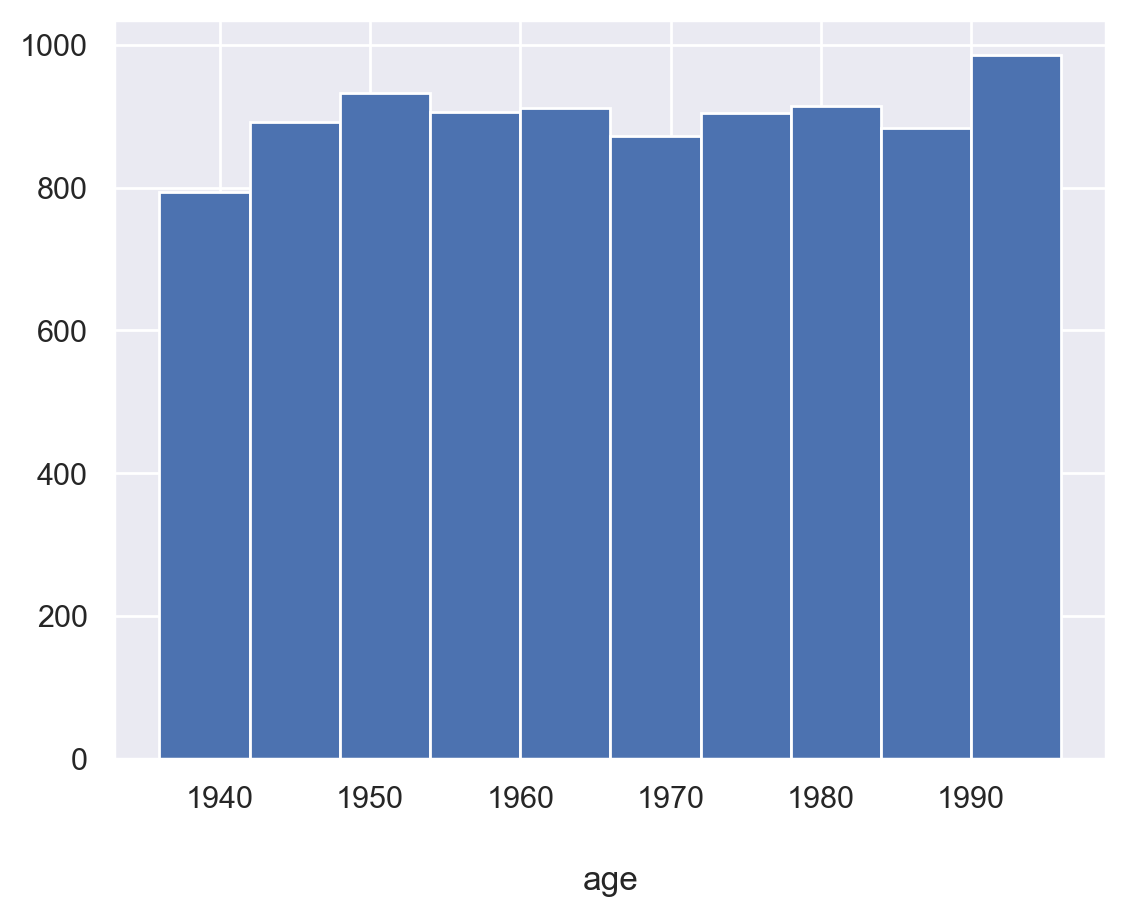

In [53]:
# Single Metric Variable Histogram
plt.hist(df["age"], bins=10)  # mess around with the bins
plt.title("age", y=-0.2)

plt.show()

Box plots elements are the first and third quartiles (Q1 and Q3), the median (Q2) and the whiskers, that stop on lowest and highest values that are not considered outliers. The formula to calculate the boundaries is: 

$$
  IQR = Q_3 - Q_1 \\\

  minimum = Q_1 - 1.5*IQR \\\

  maximum = Q_3 + 1.5*IQR 
$$

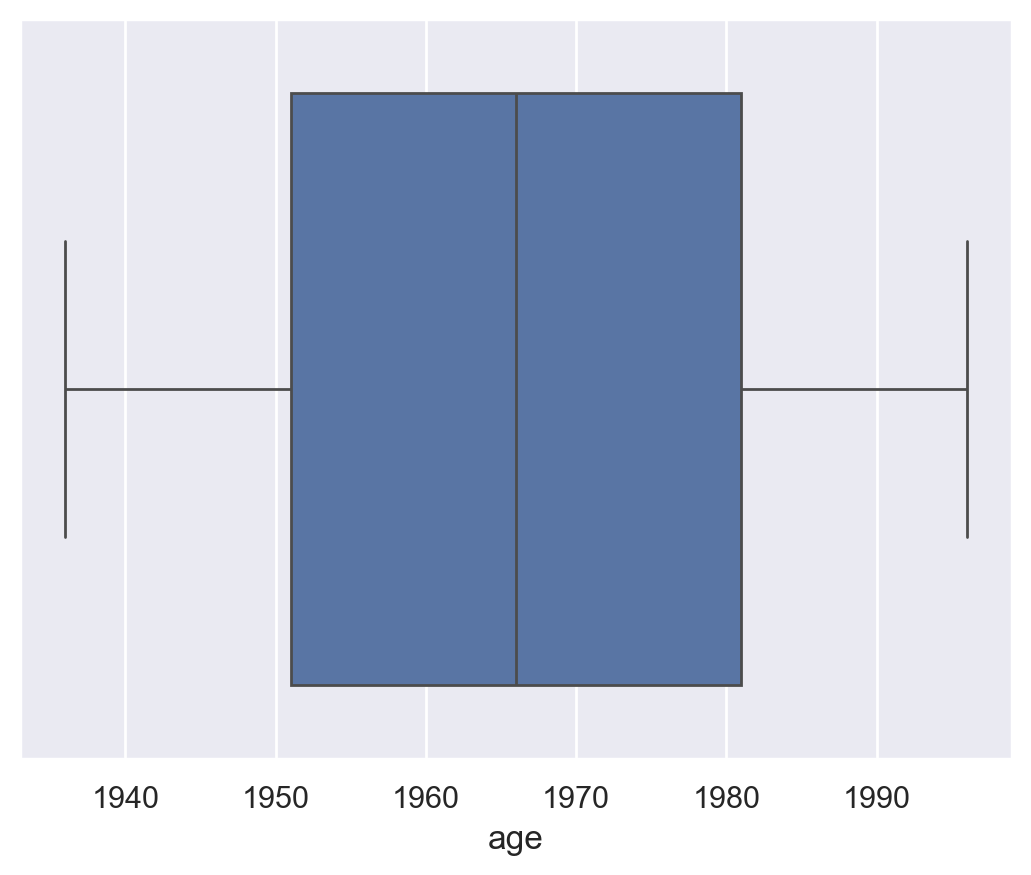

In [54]:
# Single Metric Variable Box Plot
sns.boxplot(x=df["age"])

plt.show()

What information can we extract from the plot above?

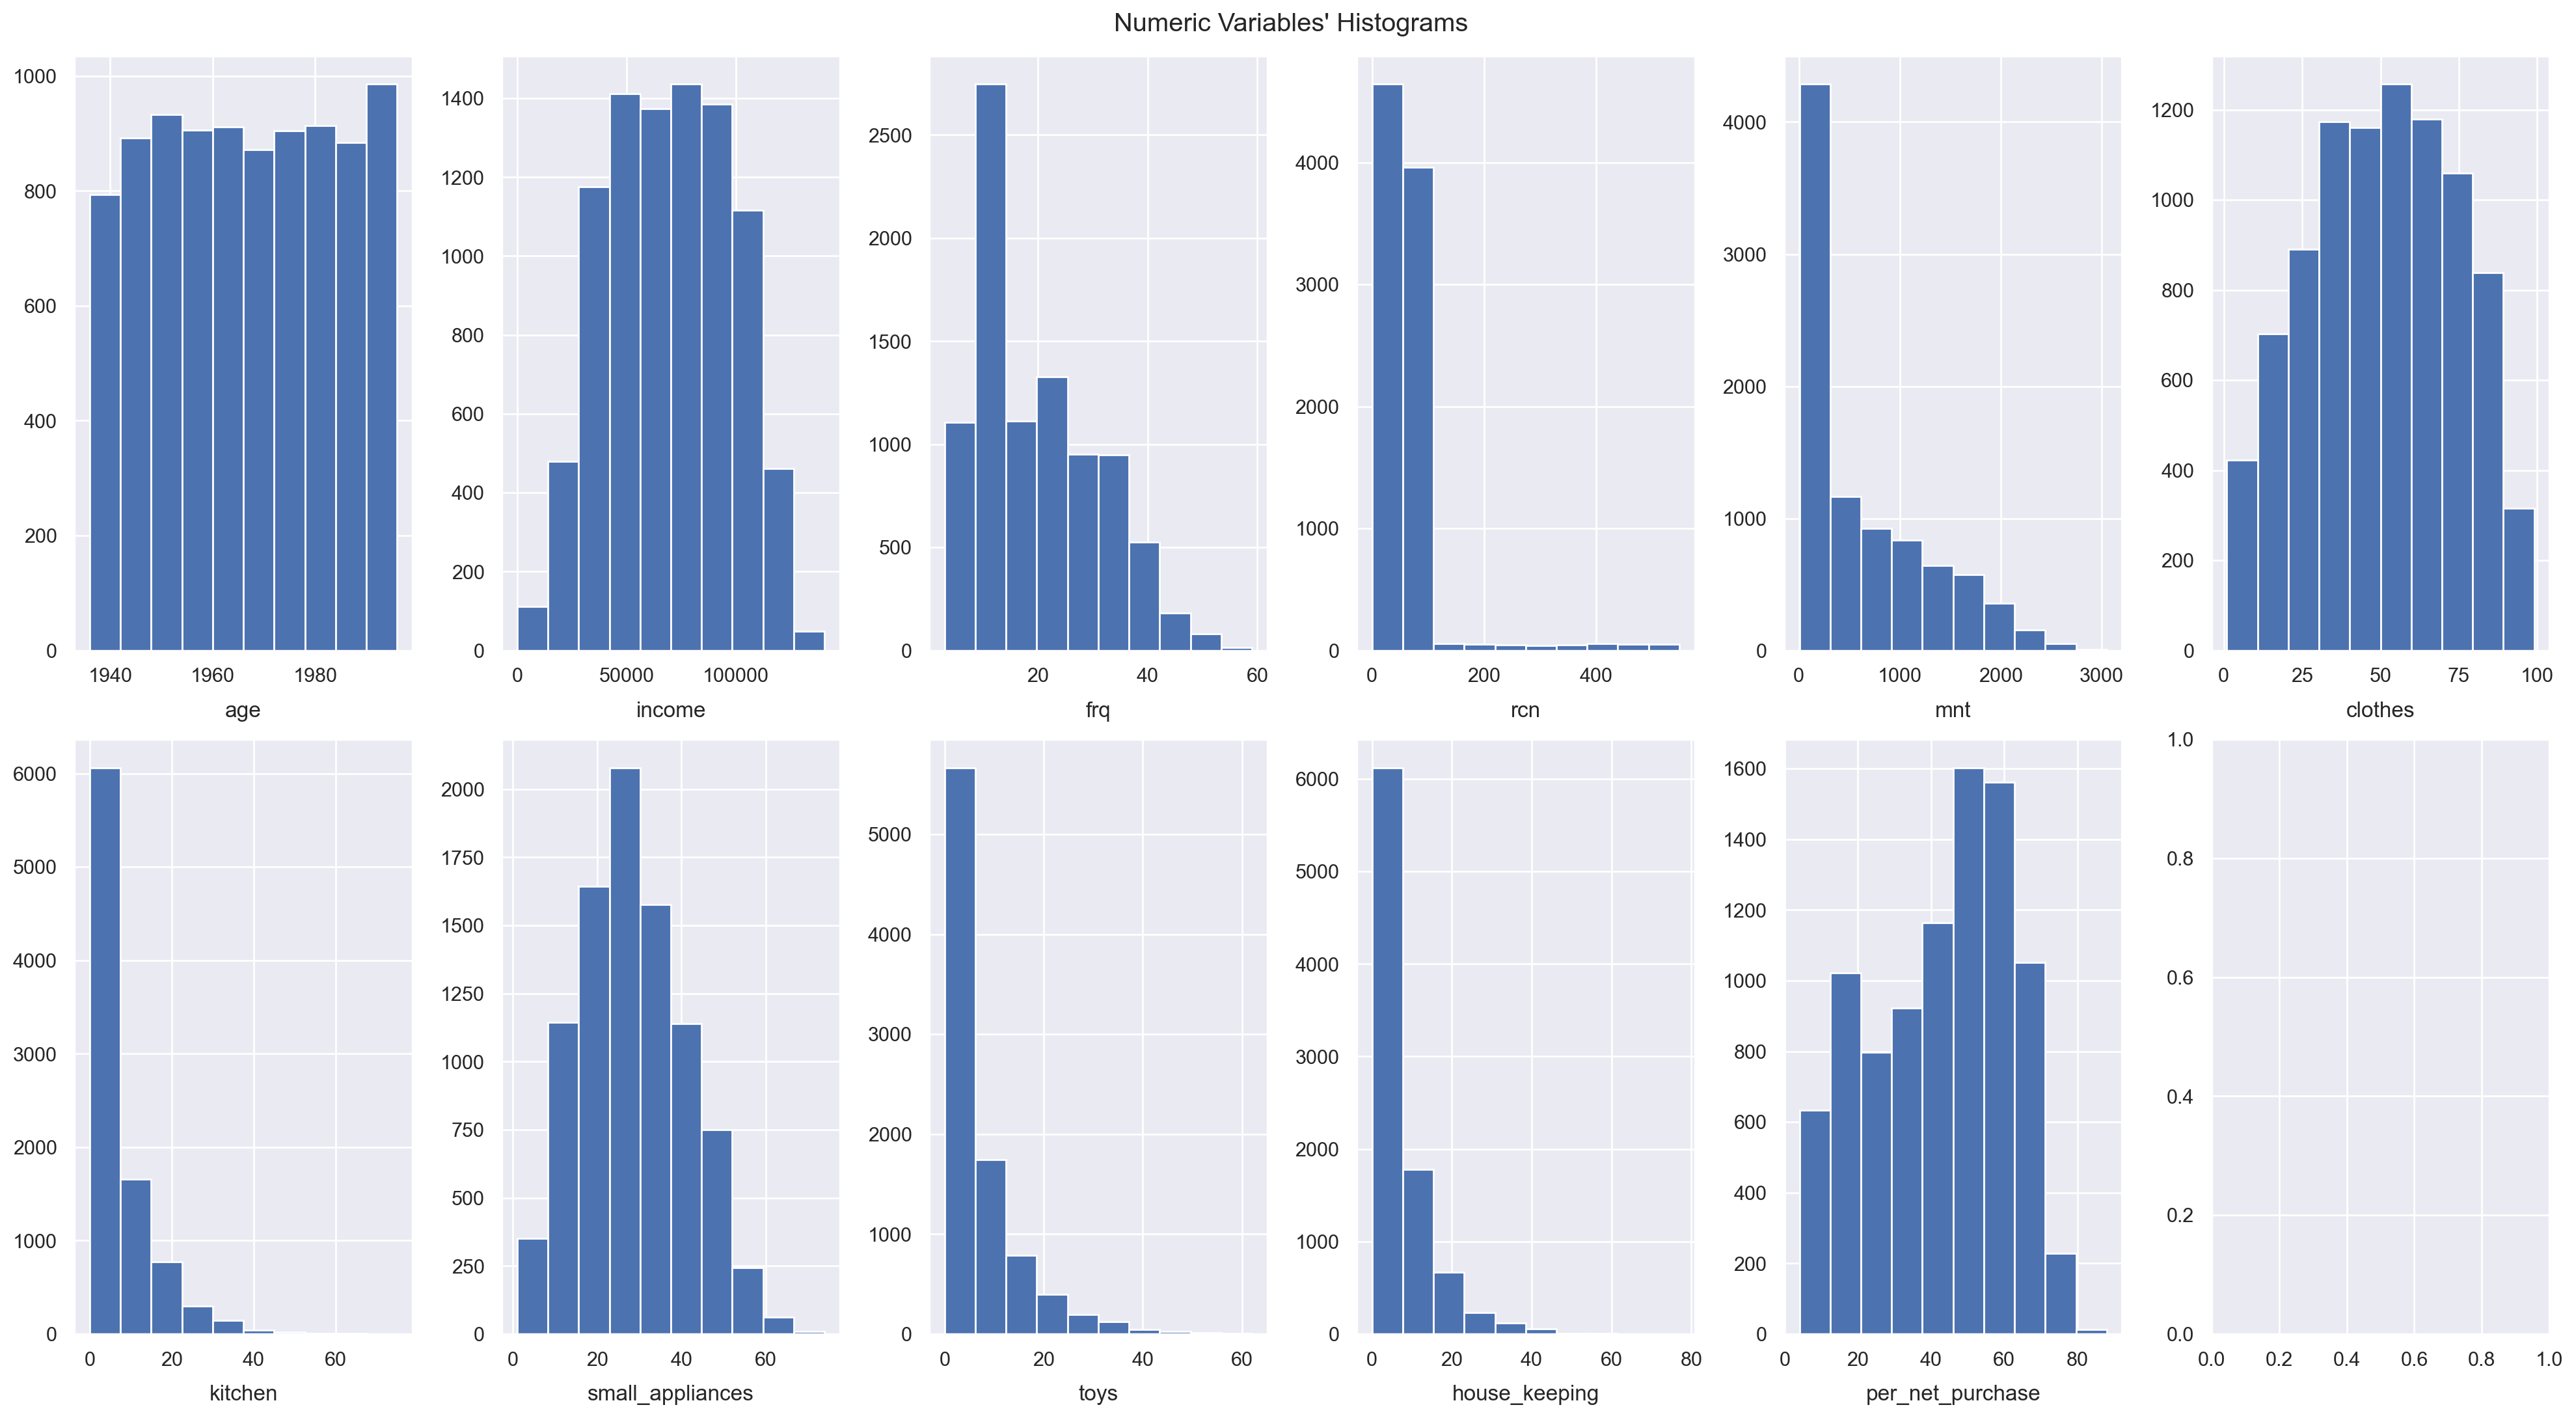

In [55]:
# Prepare figure. Create individual axes where each histogram will be placed
fig, axes = plt.subplots(2, ceil(len(metric_features) / 2), figsize=(20, 11))

# Plot data
# Iterate across axes objects and associate each histogram (hint: use the ax.hist() instead of plt.hist()):
for ax, feat in zip(axes.flatten(), metric_features): # Notice the zip() function and flatten() method
    ax.hist(df[feat])
    ax.set_title(feat, y=-0.13)
    
    
# Layout
# Add a centered title to the figure:
title = "Numeric Variables' Histograms"

plt.suptitle(title)
plt.tight_layout()

plt.show()

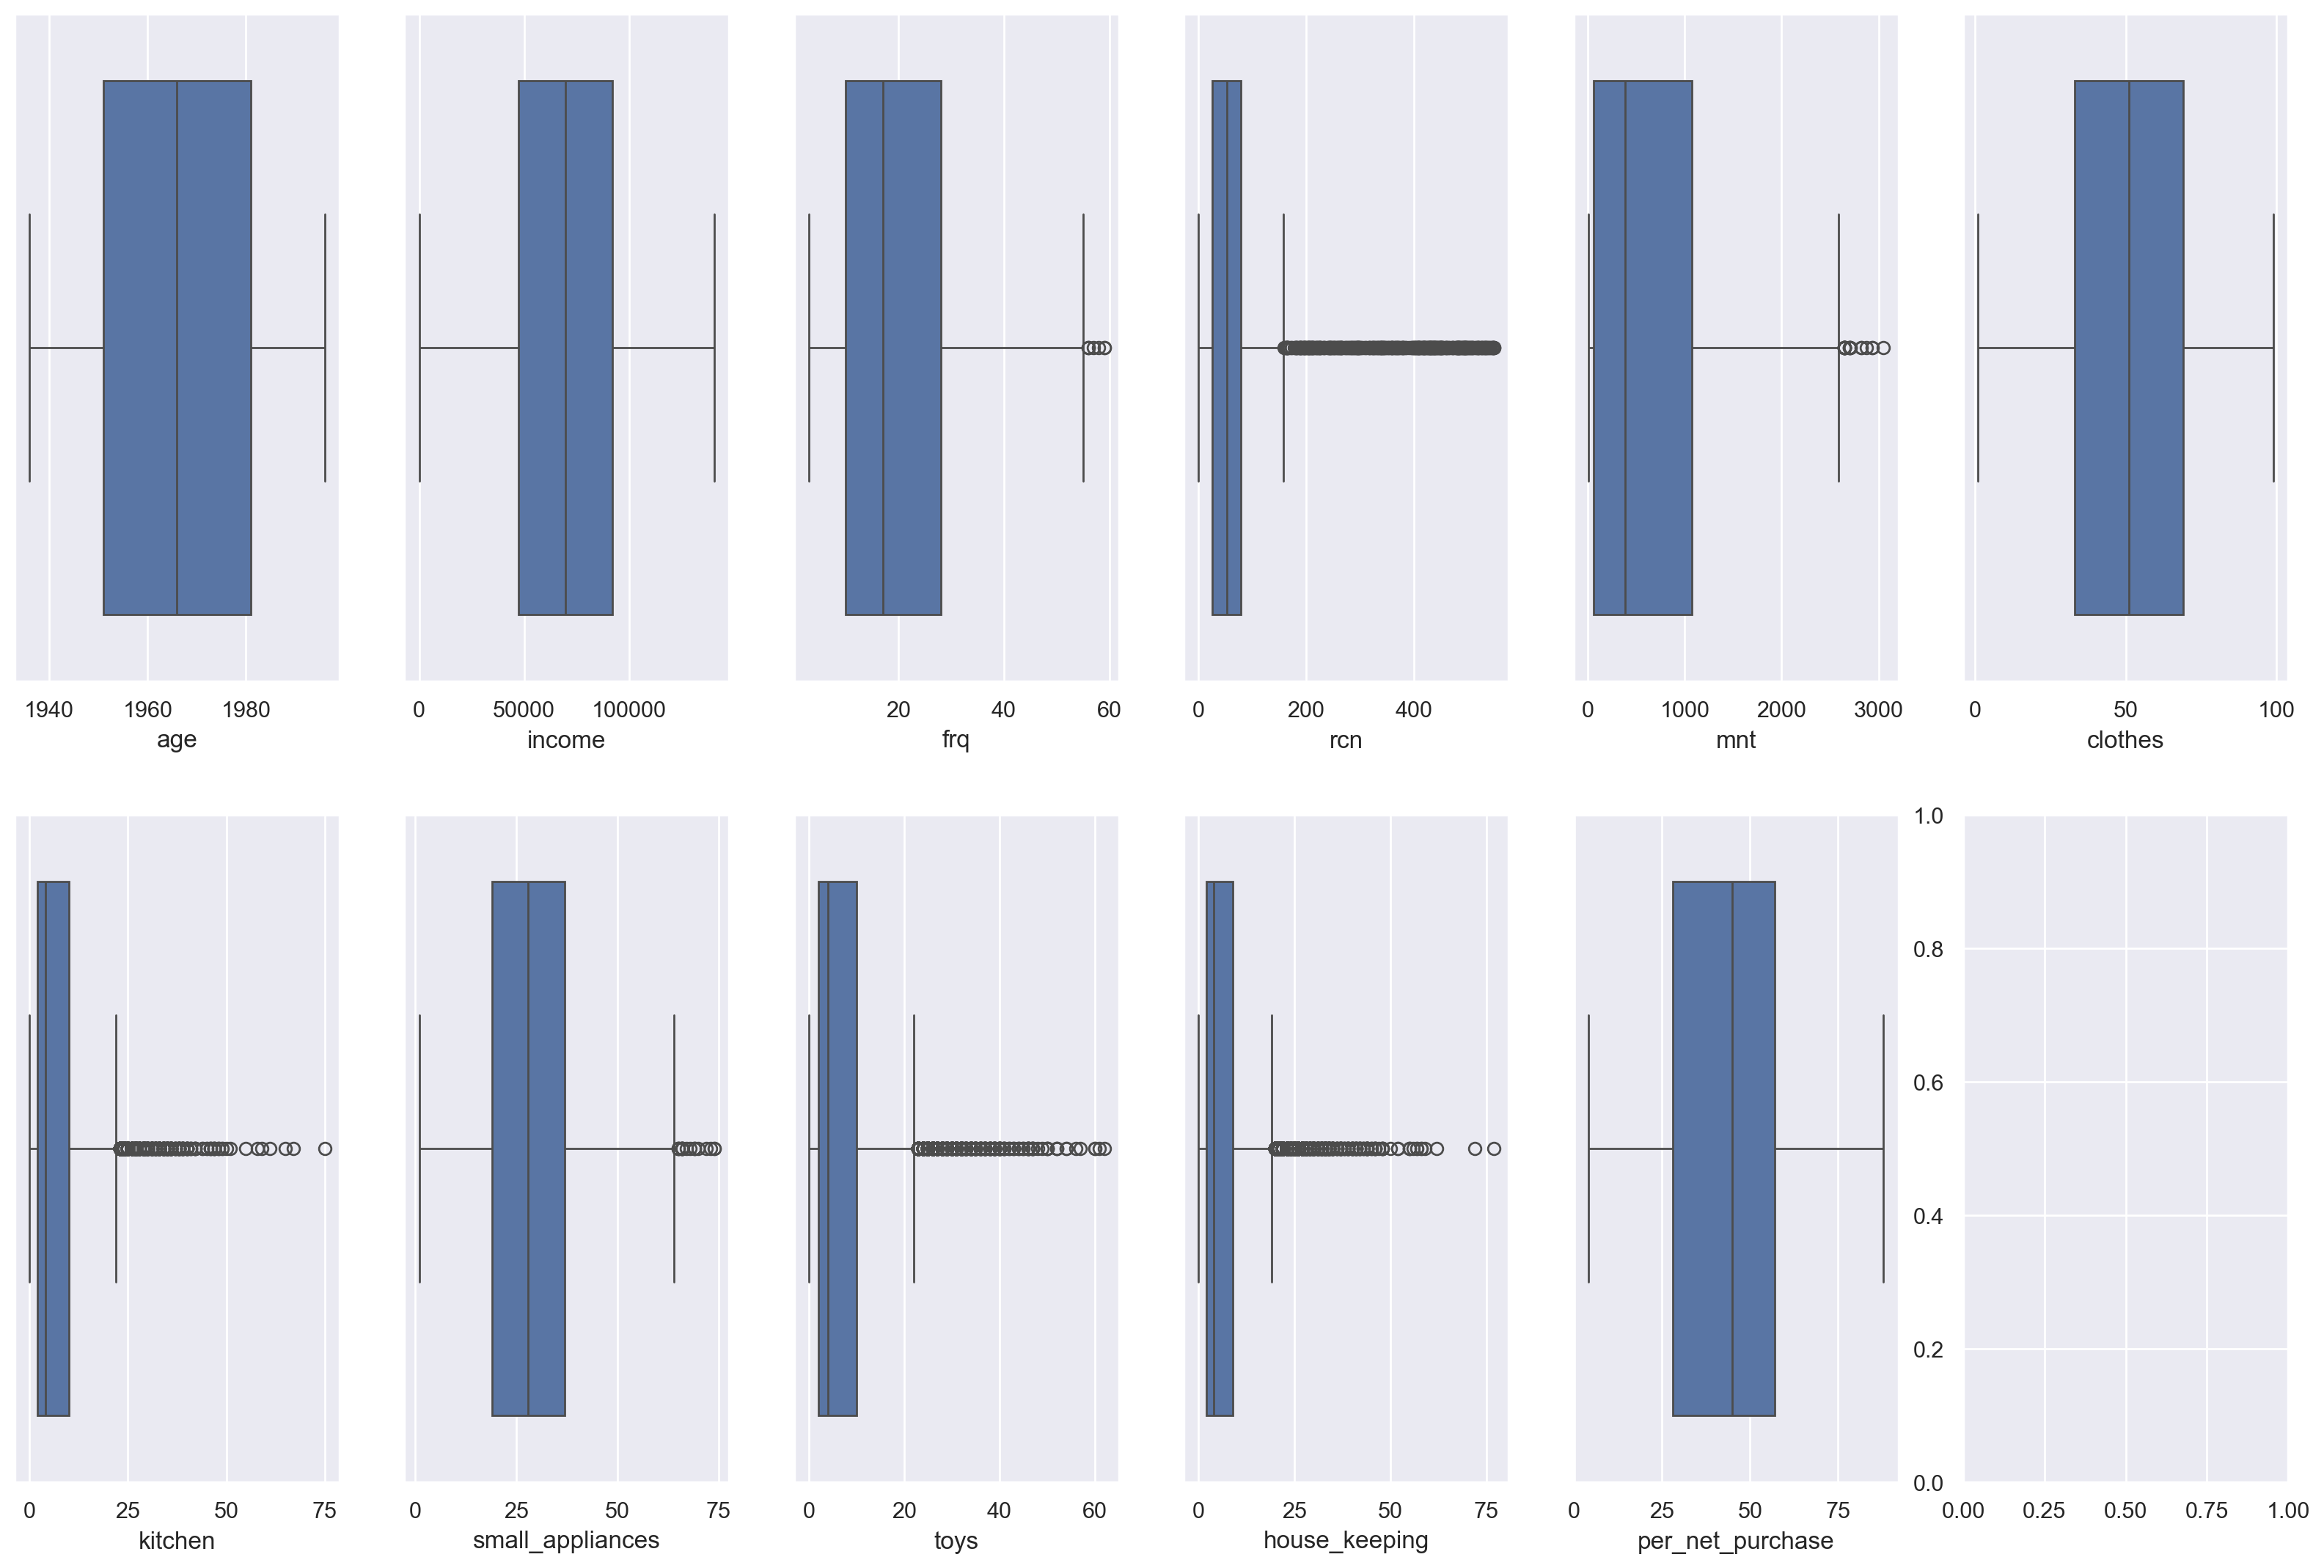

In [56]:
# Prepare figure. Create individual axes where each box plot will be placed
fig, axes = plt.subplots(2, ceil(len(metric_features) / 2), figsize=(20, 13))

# Plot data
# Iterate across axes objects and associate each box plot (hint: use the ax argument):
for ax, feat in zip(axes.flatten(), metric_features): # Notice the zip() function and flatten() method
    sns.boxplot(x=df[feat], ax=ax)
    
    
# Layout
# Add a centered title to the figure:
title = 'Numeric Variables\' Box Plots' # notice the "\"

# CODE HERE
plt.show()

### Insights:
- univariate distributions
- potential univariate outliers

--------------------------------------

### During our Exploratory Data Analysis (EDA), we must also account for:
- Coherence check
- Outliers
- Feature Engineering

### Depending on the context, various steps must be considered when performing Data Preprocessing. 

The most relevant steps are the following:
- Coherence check (find inconsistent values, missing values, outliers and any other problem you may find in your dataset)
- Data editing (fix inconsistent values)
- Data cleansing (drop observations - Outlier removal and removal of inconsistent values and/or features)
- Data wrangling (feature extraction/engineering and transformation)
- Data reduction (reducing the dimensionality of a dataset, producing summary statistics, reducing the number of records in a dataset)

## Optional Exercise

Download the [Amazing Creative Desk Coworking dataset](https://elearning.novaims.unl.pt/mod/folder/view.php?id=113931). Using the  `acdc_dataset.csv` file, perform the same exercises that we did in this notebook.

Identify the metric and non-metric features in this data.

Identify if any problems exist:

- Duplicates?
- Data types?
- Missing values?
- Strange values?
- Descriptive statistics?


In [57]:
# please use pd.read_csv()
# try to note from if the separator is , or ; or \t